# Librerias

In [1]:
import scienceplots
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import ccdproc
import astropy

import astropy.units as u
from astropy.io import fits
from astropy.wcs import WCS
from astropy.wcs.utils import proj_plane_pixel_scales
from astropy.nddata import CCDData, Cutout2D
from astropy.table import Table, QTable
from astropy.stats import sigma_clipped_stats, SigmaClip
from astropy.coordinates import SkyCoord, match_coordinates_sky
from astropy.visualization import simple_norm
from astropy.visualization import (MinMaxInterval, SqrtStretch, LogStretch, LinearStretch, ImageNormalize, ZScaleInterval)
from astropy.cosmology import FlatLambdaCDM
from matplotlib.colors import LogNorm

from os import listdir  
from os.path import join
from ccdproc import subtract_bias ,subtract_dark, flat_correct, combine
from photutils.detection import DAOStarFinder
from photutils.aperture import CircularAperture, CircularAnnulus, aperture_photometry, ApertureStats
from photutils.background import Background2D, MedianBackground
from astroquery.astrometry_net import AstrometryNet
from sklearn.mixture import GaussianMixture
from scipy.stats import norm
from scipy.stats import ks_2samp

plt.style.use('science')
%matplotlib inline

import warnings
from astropy.utils.exceptions import AstropyWarning
from astropy import log
warnings.simplefilter('ignore', category=AstropyWarning)
log.setLevel('ERROR')

# Funciones

In [2]:
def calcular_densidad_local(subdf, z_centro, cosmo):
    coords = SkyCoord(ra=subdf['target_ra'].values*u.deg,
                       dec=subdf['target_dec'].values*u.deg)
    
    idx, d2d, d3d = match_coordinates_sky(coords, coords, nthneighbor=4)
    
    d_A = cosmo.angular_diameter_distance(z_centro)
    d3_Mpc = (d2d.to(u.rad).value) * d_A.value
    
    return 3.0 / (np.pi * d3_Mpc**2)

def ecdf(data):
    x = np.sort(data)
    y = np.arange(1, len(x) + 1) / len(x)
    return x, y

# Parámetros de las Galaxias

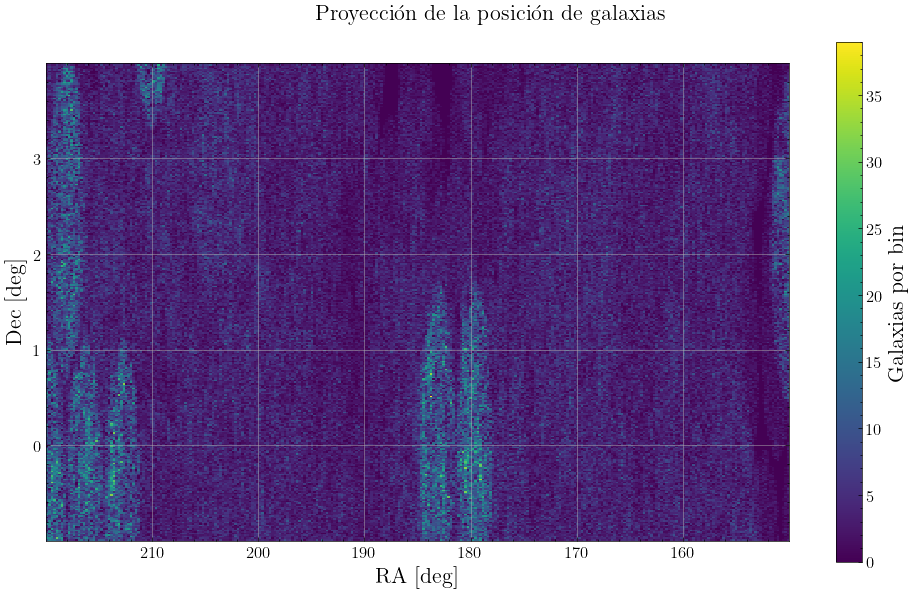

In [3]:
df = pd.read_csv('fits/hola.csv')

fig, ax = plt.subplots(figsize=(10, 6))
h = ax.hist2d(df["target_ra"], df["target_dec"], bins=300, cmap="viridis")
cbar = plt.colorbar(h[3])
cbar.set_label(label="Galaxias por bin", fontsize=16)
cbar.ax.tick_params(labelsize=12)

ax.set_xlabel("RA [deg]", fontsize=16)
ax.set_ylabel("Dec [deg]", fontsize=16)
ax.invert_xaxis()
ax.grid(True, alpha=0.7)
ax.set_aspect(9)
ax.tick_params(labelsize=12, right=True)

plt.suptitle('Proyección de la posición de galaxias', fontsize=16)
plt.tight_layout()
plt.savefig('images/4a - position_bin.pdf')
plt.show()

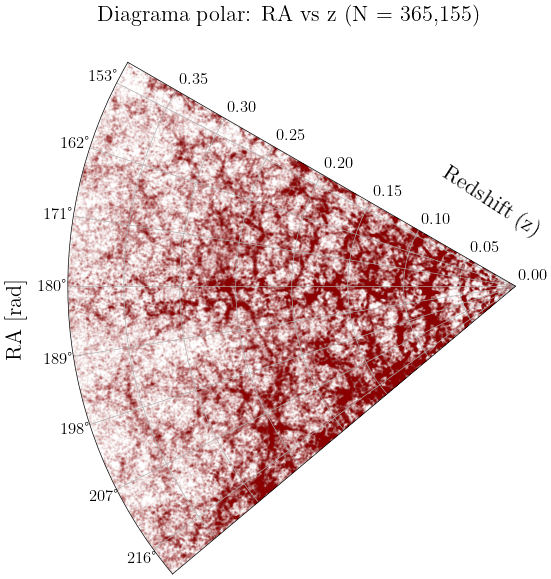

In [4]:
fig, ax = plt.subplots(figsize=(8, 6), subplot_kw={"projection": "polar"})

theta = np.deg2rad(df["target_ra"])
r = df["z"]

ax.scatter(theta, r, s=0.4, alpha=0.05, color="darkred", rasterized=True)
ax.set_thetamin(150)
ax.set_thetamax(220)
ax.set_rmax(df['z'].max())

ax.set_ylabel("RA [rad]", fontsize=16)
ax.set_xlabel('Redshift (z)', rotation=-33, fontsize=16, labelpad=-125, loc='right')
ax.xaxis.set_label_position('top')
ax.tick_params(labelsize=12)
ax.set_title(f"Diagrama polar: RA vs z (N = {len(df):,})", pad=30, fontsize=16)

plt.tight_layout()
plt.savefig("images/4b - polar_diagram.png", dpi=300)
plt.show()

In [5]:
df["mag_g"] = 22.5 - 2.5 * np.log10(df["flux_g"])
df["sigma_mag_g"] = 1.085736 / (df["flux_g"] * np.sqrt(df["flux_ivar_g"]))

df["mag_r"] = 22.5 - 2.5 * np.log10(df["flux_r"])
df["sigma_mag_r"] = 1.085736 / (df["flux_r"] * np.sqrt(df["flux_ivar_r"]))

df["mag_z"] = 22.5 - 2.5 * np.log10(df["flux_z"])
df["sigma_mag_z"] = 1.085736 / (df["flux_z"] * np.sqrt(df["flux_ivar_z"]))

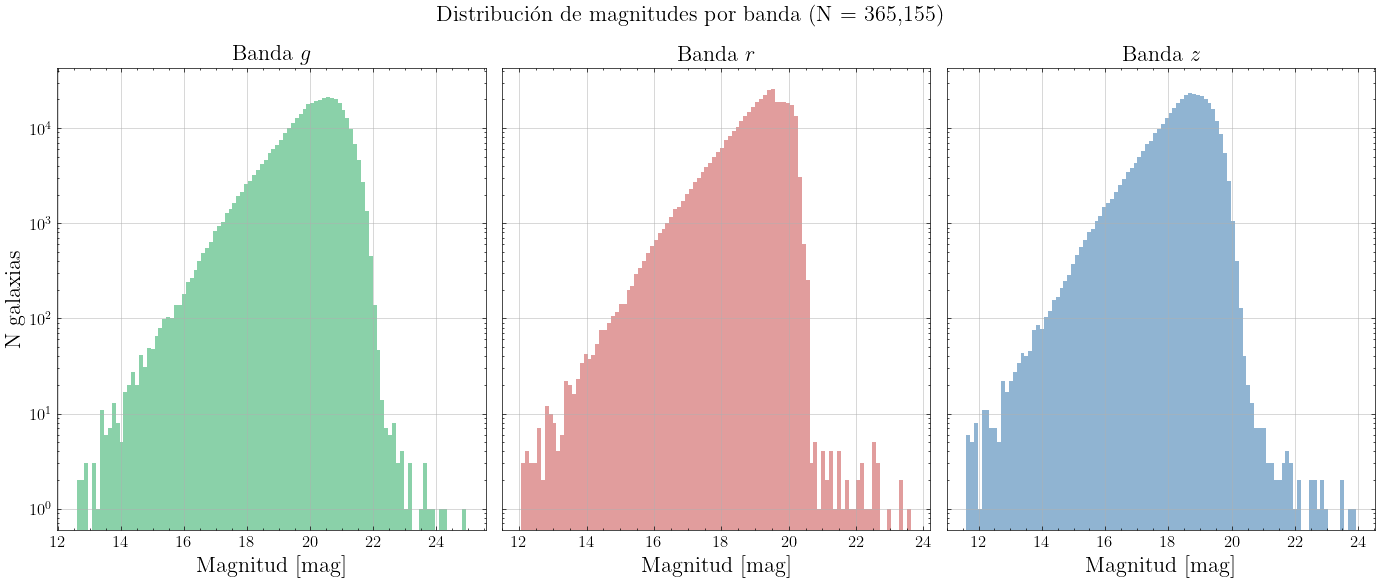

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 6), sharey=True)
bandas = ["mag_g", "mag_r", "mag_z"]
titulos = ["Banda $g$", "Banda $r$", "Banda $z$"]
colores = ["mediumseagreen", "indianred", "steelblue"]

for i, (ax, banda, titulo, color) in enumerate(zip(axes, bandas, titulos, colores)):
    ax.hist(df[banda], bins=100, color=color, alpha=0.6)
    ax.set_title(titulo, fontsize=16)
    ax.set_xlabel("Magnitud [mag]", fontsize=16)
    ax.set_yscale("log")
    ax.grid(True, alpha=0.7)
    ax.tick_params(labelsize=12)

axes[0].set_ylabel("N galaxias", fontsize=16)
fig.suptitle(f"Distribución de magnitudes por banda (N = {len(df):,})", fontsize=16)
plt.tight_layout()
plt.savefig("images/4c - mag_individuales.pdf", dpi=150)
plt.show()

# Propiedades globales

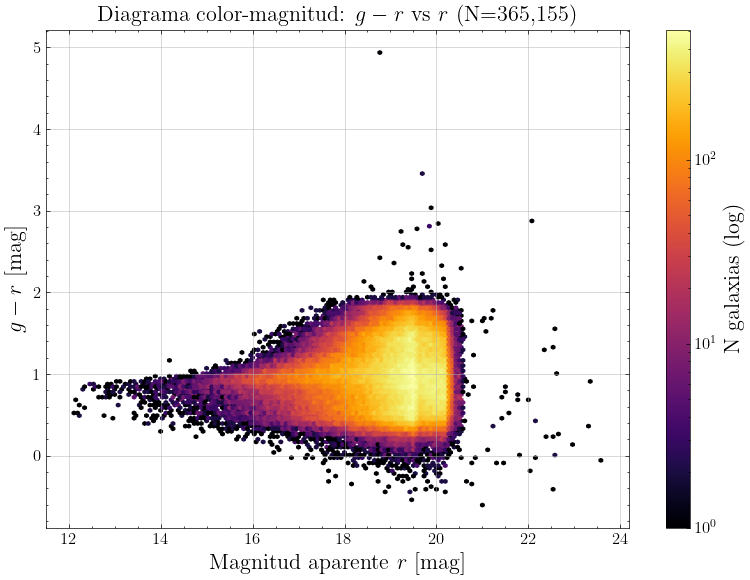

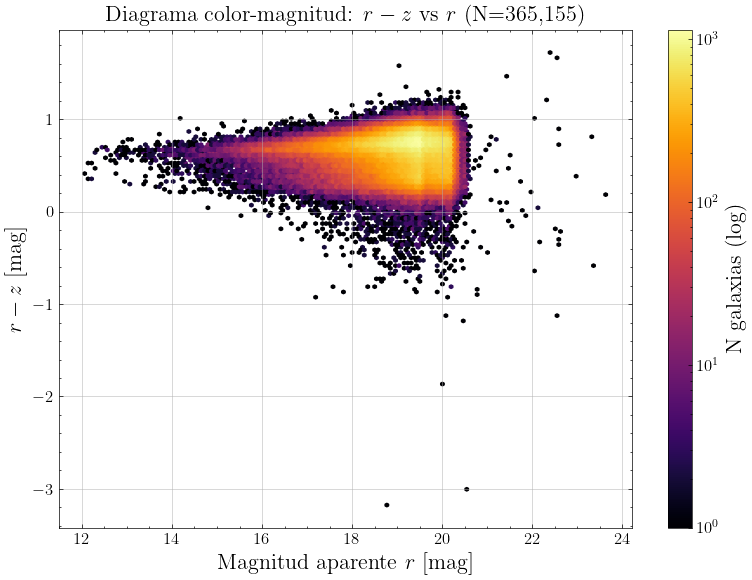

In [7]:
color_1 = df['mag_g'] - df['mag_r']
color_2 = df['mag_r'] - df['mag_z']

# g - r
fig, ax = plt.subplots(figsize=(8, 6))
hb = ax.hexbin(df['mag_r'], color_1, gridsize=150, bins='log', cmap='inferno', mincnt=1)
cbar = plt.colorbar(hb, ax=ax)
cbar.set_label('N galaxias (log)', fontsize=16)
cbar.ax.tick_params(labelsize=12)

ax.set_xlabel('Magnitud aparente $r$ [mag]', fontsize=16)
ax.set_ylabel('$g - r$ [mag]', fontsize=16)
ax.tick_params(labelsize=12)
ax.grid(True, alpha=0.7)
ax.set_title(f'Diagrama color-magnitud: $g-r$ vs $r$ (N={len(df):,})', fontsize=16)

plt.tight_layout()
plt.savefig('images/5a - gr_aparente.pdf', dpi=150)
plt.show()

# r - z
fig, ax = plt.subplots(figsize=(8, 6))
hb = ax.hexbin(df['mag_r'], color_2, gridsize=150, bins='log', cmap='inferno', mincnt=1)
cbar = plt.colorbar(hb, ax=ax)
cbar.set_label('N galaxias (log)', fontsize=16)
cbar.ax.tick_params(labelsize=12)

ax.set_xlabel('Magnitud aparente $r$ [mag]', fontsize=16)
ax.set_ylabel('$r - z$ [mag]', fontsize=16)
ax.tick_params(labelsize=12)
ax.grid(True, alpha=0.7)
ax.set_title(f'Diagrama color-magnitud: $r-z$ vs $r$ (N={len(df):,})', fontsize=16)

plt.tight_layout()
plt.savefig('images/5a - rz_aparente.pdf', dpi=150)
plt.show()

In [8]:
# Distancias! 

h0 = 70
c = 300000

# Hubble:
hubble = pd.DataFrame()
hubble['d'] = (df['z']*c)/h0 # Mpc !!!!

mag_n = ['g', 'r', 'z']
for mag in mag_n:
    nombre = 'mag_' + mag
    hubble[nombre] = df[nombre] - 5*np.log10(hubble['d']) - 25

# astropy.cosmology:
cosmology = pd.DataFrame()
cosmo = FlatLambdaCDM(H0=70 * u.km / (u.s * u.Mpc), Om0 = 0.3, Tcmb0 = 2.725 * u.K)
cosmology['d'] = cosmo.luminosity_distance(df['z']).value
for mag in mag_n:
    nombre = 'mag_' + mag
    cosmology[nombre] = df[nombre] - 5*np.log10(cosmology['d']) - 25

In [9]:
diff_d_rel = 100.0 * (hubble['d'] - cosmology['d']) / cosmology['d']
diff_M_r = hubble['mag_r'] - cosmology['mag_r']

print(f'Error porcentual promedio = {np.mean(diff_d_rel):.3f}')

Error porcentual promedio = -12.823


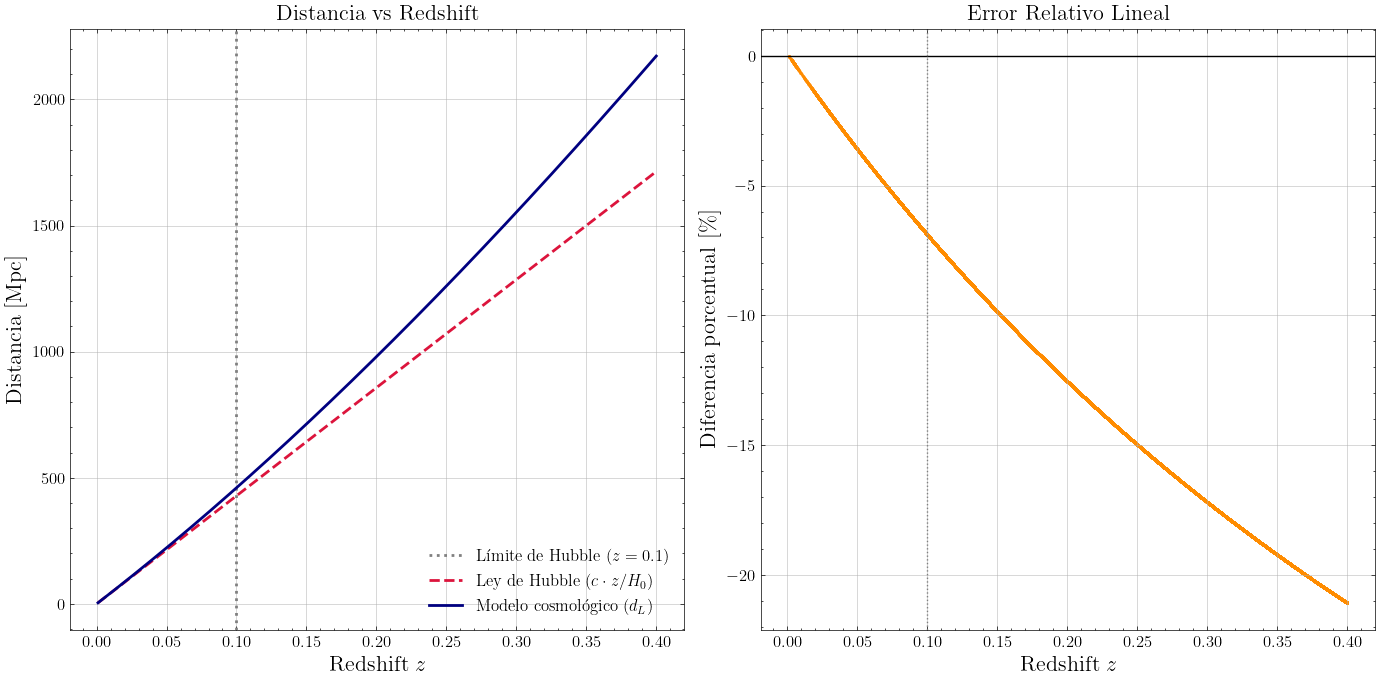

In [23]:
idx_sort = np.argsort(df['z'].values)
z_sorted = df['z'].values[idx_sort]
d_hub_sorted = hubble['d'].values[idx_sort]
d_cosmo_sorted = cosmology['d'].values[idx_sort]

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].axvline(0.1, color='gray', linestyle=':', lw=2, label=r'Límite de Hubble ($z = 0.1$)')
axes[0].plot(z_sorted, d_hub_sorted, label=r'Ley de Hubble ($c \cdot z/H_0$)', color='crimson', lw=2, linestyle='--')
axes[0].plot(z_sorted, d_cosmo_sorted, label=r'Modelo cosmológico ($d_L$)', color='navy', lw=2)
axes[0].set_xlabel('Redshift $z$', fontsize=16)
axes[0].set_ylabel('Distancia [Mpc]', fontsize=16)
axes[0].set_title('Distancia vs Redshift', fontsize=16)
axes[0].legend(fontsize=12)
axes[0].tick_params(labelsize=12)
axes[0].grid(True, alpha=0.7)

axes[1].scatter(df['z'], diff_d_rel, s=0.5, alpha=0.3, color='darkorange')
axes[1].axhline(0, color='black', linestyle='-', lw=1)
axes[1].axvline(0.1, color='gray', linestyle=':')
axes[1].set_xlabel('Redshift $z$', fontsize=16)
axes[1].set_ylabel(r'Diferencia porcentual [\%]', fontsize=16)
axes[1].set_title('Error Relativo Lineal', fontsize=16)
axes[1].grid(True, alpha=0.7)
axes[1].tick_params(labelsize=12)

plt.tight_layout()
plt.savefig('images/5b - error.png')
plt.show()

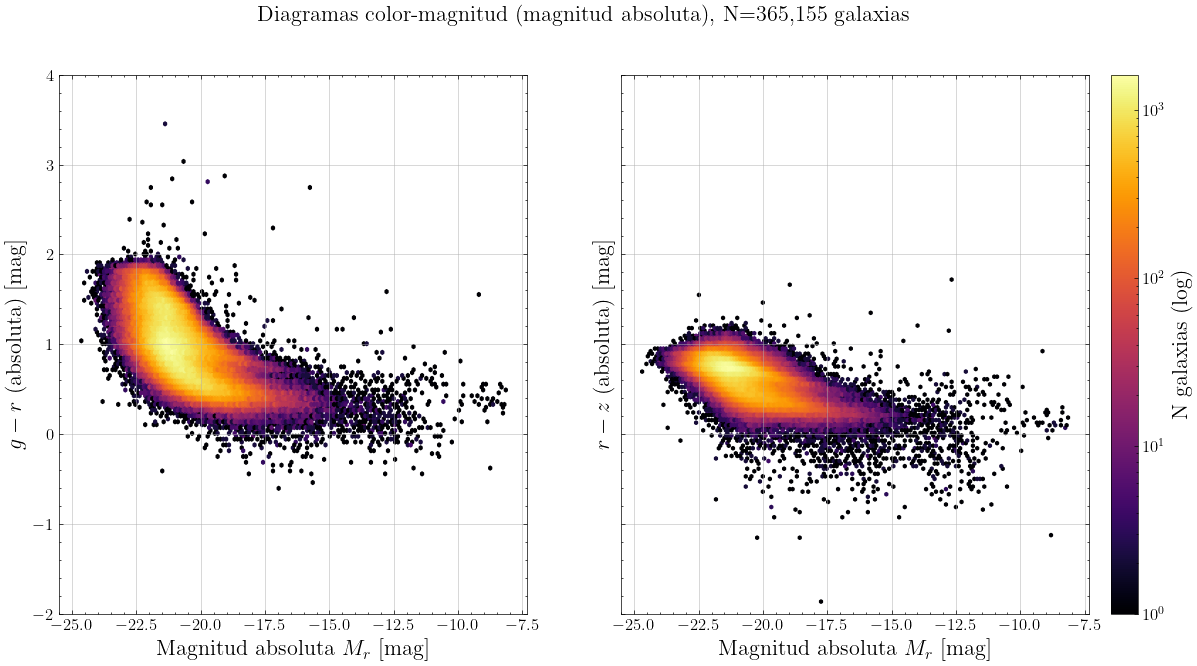

In [11]:
color_1_abs = cosmology['mag_g'] - cosmology['mag_r']
color_2_abs = cosmology['mag_r'] - cosmology['mag_z']

fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharey=True)

hb0 = axes[0].hexbin(cosmology['mag_r'], color_1_abs, gridsize=150, bins='log', 
                       cmap='inferno', mincnt=1)
axes[0].set_xlabel('Magnitud absoluta $M_r$ [mag]', fontsize=16)
axes[0].set_ylabel('$g - r$ (absoluta) [mag]', fontsize=16)
axes[0].tick_params(labelsize=12)
axes[0].grid(True, alpha=0.7)
axes[0].set_ylim(-2, 4)

hb1 = axes[1].hexbin(cosmology['mag_r'], color_2_abs, gridsize=150, bins='log', 
                       cmap='inferno', mincnt=1)
axes[1].set_xlabel('Magnitud absoluta $M_r$ [mag]', fontsize=16)
axes[1].set_ylabel('$r - z$ (absoluta) [mag]', fontsize=16)
axes[1].tick_params(labelsize=12)
axes[1].grid(True, alpha=0.7)

cbar = fig.colorbar(hb1, ax=axes, location='right', fraction=0.03, pad=0.02)
cbar.set_label('N galaxias (log)', fontsize=16)
cbar.ax.tick_params(labelsize=12)

plt.suptitle(f'Diagramas color-magnitud (magnitud absoluta), N={len(df):,} galaxias', fontsize=16)
plt.savefig('images/5c - color_vs_magnitud_absoluta.pdf', dpi=150, bbox_inches='tight')
plt.show()

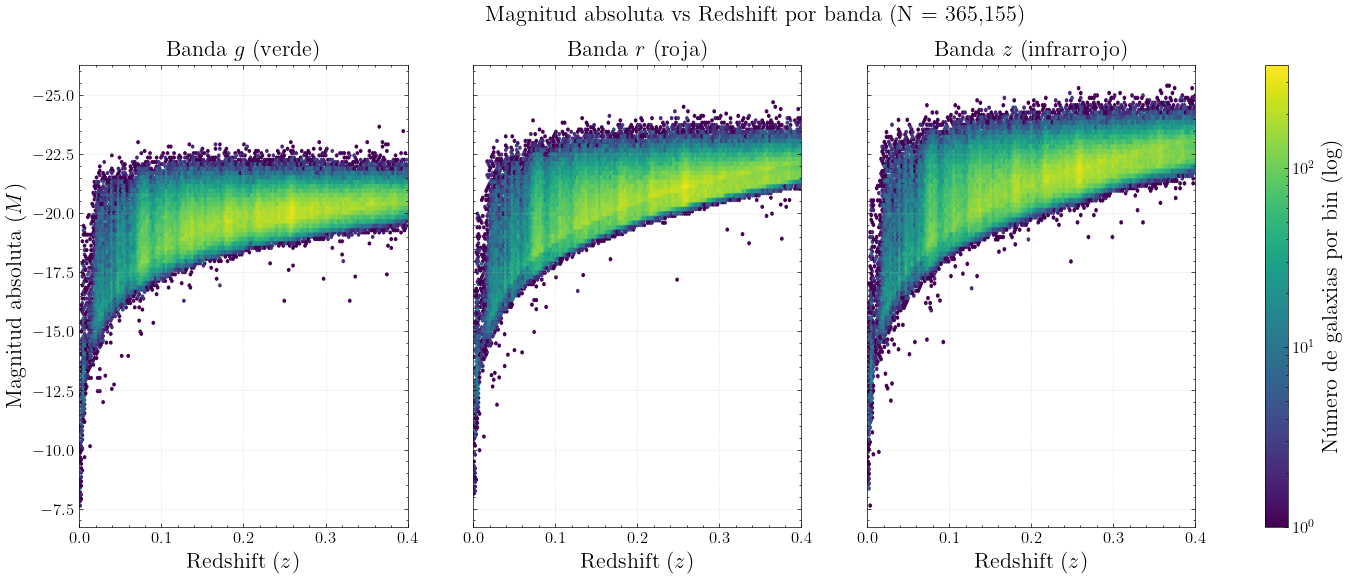

In [12]:
bandas = ["mag_g", "mag_r", "mag_z"]
titulos_bandas = ["Banda $g$ (verde)", "Banda $r$ (roja)", "Banda $z$ (infrarrojo)"]

max_counts = []
for banda in bandas:
    counts, _, _ = np.histogram2d(df['z'], cosmology[banda], bins=150)
    max_counts.append(counts.max())
norm_compartida = LogNorm(vmin=1, vmax=np.max(max_counts))


fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
for ax, banda, titulo in zip(axes, bandas, titulos_bandas):
    hb = ax.hexbin(
        df['z'], 
        cosmology[banda], 
        gridsize=150, 
        norm=norm_compartida,  
        cmap='viridis',        
        mincnt=1
    )
    ax.set_title(titulo, fontsize=16)
    ax.set_xlabel('Redshift ($z$)', fontsize=16)
    ax.tick_params(labelsize=12)
    ax.set_xlim(0, 0.4)
    ax.grid(True, alpha=0.3, linestyle='--')

axes[0].set_ylabel('Magnitud absoluta ($M$)', fontsize=16)
axes[0].invert_yaxis()

# cbar
cbar = fig.colorbar(hb, ax=axes)
cbar.set_label('Número de galaxias por bin (log)', fontsize=16)
cbar.ax.tick_params(labelsize=12)

plt.suptitle(f'Magnitud absoluta vs Redshift por banda (N = {len(df):,})', fontsize=16, y=0.98)
plt.savefig('images/5e - mag_abs_vs_z.pdf', dpi=150, bbox_inches='tight')
plt.show()

# Separación de poblaciones

In [13]:
z_vals = df['z'].values
color = color_1_abs.values

n_bins = 30 # regiones
z_bins = np.linspace(z_vals.min(), z_vals.max(), n_bins + 1)
z_centers = 0.5 * (z_bins[:-1] + z_bins[1:])

umbral_por_bin = []
bins_validos = []

for i in range(n_bins):
    mask = (z_vals >= z_bins[i]) & (z_vals < z_bins[i+1])
    c = color[mask]
    c = c[np.isfinite(c)]    
    
    if len(c) < 200:
        continue
    
    gmm = GaussianMixture(n_components=2, random_state=0)
    gmm.fit(c.reshape(-1, 1))
    
    medias = gmm.means_.flatten()
    sigmas = np.sqrt(gmm.covariances_.flatten())
    pesos = gmm.weights_.flatten()
    
    orden = np.argsort(medias)
    medias, sigmas, pesos = medias[orden], sigmas[orden], pesos[orden]
    
    c_grid = np.linspace(medias[0], medias[1], 500)
    pdf_total = (pesos[0]*norm.pdf(c_grid, medias[0], sigmas[0]) +
                 pesos[1]*norm.pdf(c_grid, medias[1], sigmas[1]))
    corte = c_grid[np.argmin(pdf_total)]
    
    umbral_por_bin.append(corte)
    bins_validos.append(z_centers[i])

umbral_por_bin = np.array(umbral_por_bin)
bins_validos = np.array(bins_validos)

Umbral(z) = 2.732 * z + 0.482


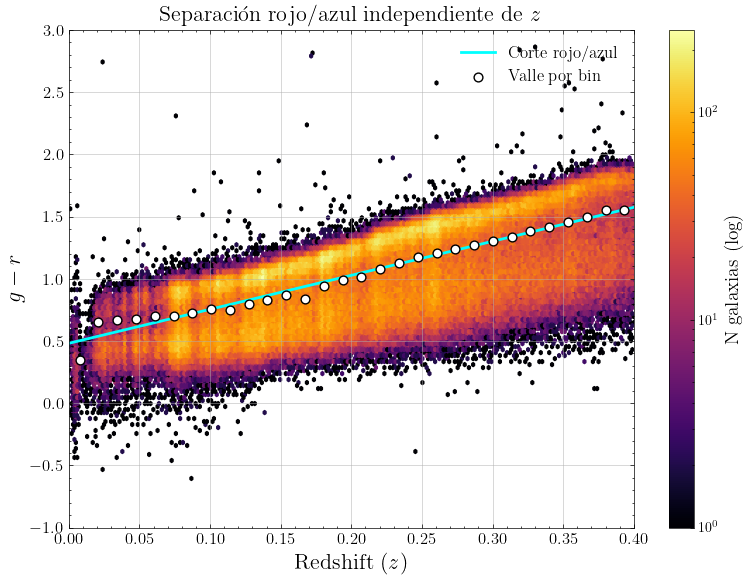

poblacion
azul    204314
roja    160841
Name: count, dtype: int64


In [14]:
# ajuste lineal
coef = np.polyfit(bins_validos, umbral_por_bin, deg=1)
umbral_fit = np.poly1d(coef)

print(f"Umbral(z) = {coef[0]:.3f} * z + {coef[1]:.3f}")

fig, ax = plt.subplots(figsize=(8, 6))
hb = ax.hexbin(df['z'], color_1_abs, gridsize=200, bins='log', cmap='inferno', mincnt=1)
cbar = plt.colorbar(hb, ax=ax)
cbar.set_label('N galaxias (log)', fontsize=14)

z_line = np.linspace(z_vals.min(), z_vals.max(), 100)
ax.plot(z_line, umbral_fit(z_line), color='cyan', lw=2, label='Corte rojo/azul')
ax.scatter(bins_validos, umbral_por_bin, color='white', edgecolor='black', 
           zorder=5, label='Valle por bin', s=40)

ax.set_ylim(-1, 3)
ax.set_xlim(0, 0.4)
ax.set_xlabel('Redshift ($z$)', fontsize=16)
ax.set_ylabel('$g-r$', fontsize=16)
ax.legend(fontsize=12)
ax.set_title('Separación rojo/azul independiente de $z$', fontsize=16)
ax.grid(True, alpha=0.7)
ax.tick_params(labelsize=12)

plt.tight_layout()
plt.savefig('images/6 - red_blue_cut.pdf', dpi=150)
plt.show()

umbral_individual = umbral_fit(df['z'])
df['poblacion'] = np.where(color_1_abs > umbral_individual, 'roja', 'azul')

print(df['poblacion'].value_counts())

poblacion
azul            146062
roja            127804
green_valley     91289
Name: count, dtype: int64


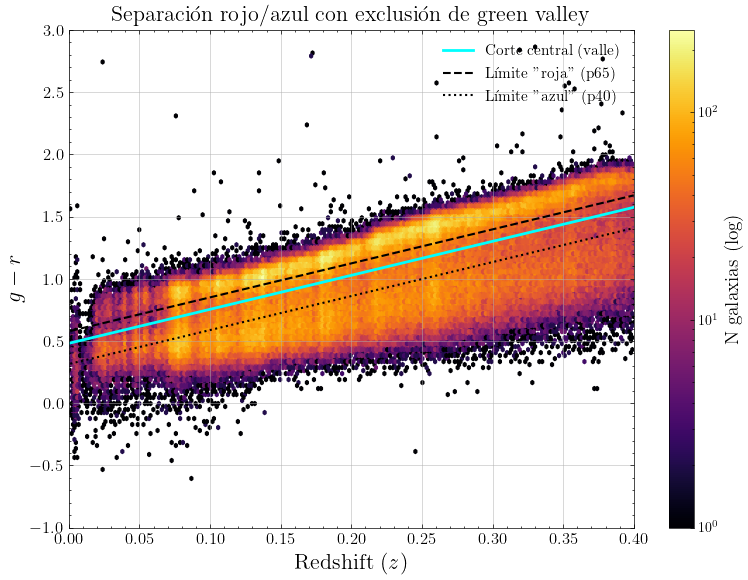

In [15]:
residual_color = color_1_abs - umbral_fit(df['z'])
p_bajo = np.percentile(residual_color, 40)
p_alto = np.percentile(residual_color, 65)

df['poblacion'] = np.select(
    [residual_color <= p_bajo, residual_color >= p_alto],
    ['azul', 'roja'],
    default='green_valley'
)
print(df['poblacion'].value_counts())

fig, ax = plt.subplots(figsize=(8, 6))
hb = ax.hexbin(df['z'], color_1_abs, gridsize=200, bins='log', cmap='inferno', mincnt=1)
cbar = plt.colorbar(hb, ax=ax)
cbar.set_label('N galaxias (log)', fontsize=14)

z_line = np.linspace(z_vals.min(), z_vals.max(), 100)
ax.plot(z_line, umbral_fit(z_line), color='cyan', lw=2, label='Corte central (valle)')
ax.plot(z_line, umbral_fit(z_line) + p_alto, color='black', lw=1.5, linestyle='--', label='Límite "roja" (p65)')
ax.plot(z_line, umbral_fit(z_line) + p_bajo, color='black', lw=1.5, linestyle=':', label='Límite "azul" (p40)')

ax.set_ylim(-1, 3)
ax.set_xlim(0, 0.4)
ax.set_xlabel('Redshift ($z$)', fontsize=16)
ax.set_ylabel('$g-r$', fontsize=16)
ax.legend(fontsize=11)
ax.set_title('Separación rojo/azul con exclusión de green valley', fontsize=16)
ax.grid(True, alpha=0.7)
ax.tick_params(labelsize=12)

plt.tight_layout()
plt.savefig('images/6 - red_blue_cut_percentiles.pdf', dpi=150)
plt.show()

# Análisis de densidades

In [16]:
z_centro = 0.25
dz = 0.01
mask_slice = (df['z'] >= z_centro - dz/2) & (df['z'] < z_centro + dz/2)
mask_slice &= (df['target_ra'].between(170, 190)) & (df['target_dec'].between(0, 2))

df['color_gr'] = (cosmology['mag_g'] - cosmology['mag_r']).values
sub = df.loc[mask_slice].copy().reset_index(drop=True)
print(f"Galaxias en la rebanada: {len(sub)}")

coords = SkyCoord(ra=sub['target_ra'].values*u.deg, 
                   dec=sub['target_dec'].values*u.deg)

idx, d2d, d3d = match_coordinates_sky(coords, coords, nthneighbor=4)
d_A = cosmo.angular_diameter_distance(z_centro)
d3_Mpc = (d2d.to(u.rad).value) * d_A.value

sub['d3_Mpc'] = d3_Mpc
sub['densidad_local'] = 3.0 / (np.pi * sub['d3_Mpc']**2)

print(sub['densidad_local'].describe())

Galaxias en la rebanada: 1680
count    1680.000000
mean       45.433624
std       337.791117
min         0.003607
25%         0.291257
50%         1.314515
75%         6.452602
max      6183.890417
Name: densidad_local, dtype: float64


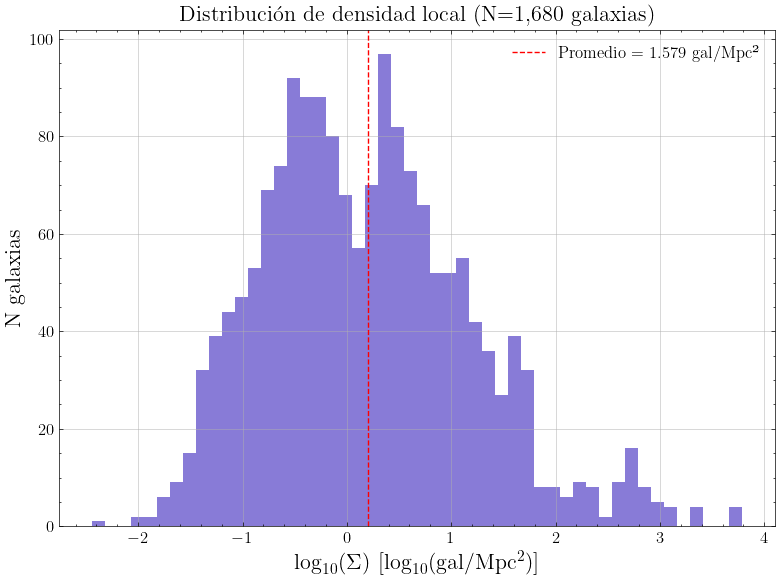

Media aritmética = 45.434 gal/Mpc²
Media geométrica (vía log) = 1.579 gal/Mpc²


In [17]:
log_densidad = np.log10(sub['densidad_local'])

fig, ax = plt.subplots(figsize=(8, 6))
ax.hist(log_densidad, bins=50, color='slateblue', alpha=0.8)
ax.axvline(log_densidad.mean(), color='red', linestyle='--',
           label=f"Promedio = {10**log_densidad.mean():.3f} gal/Mpc²")
ax.set_xlabel(r'$\log_{10}(\Sigma)$  [$\log_{10}$(gal/Mpc$^2$)]', fontsize=16)
ax.set_ylabel('N galaxias', fontsize=16)
ax.legend(fontsize=12)
ax.set_title(f'Distribución de densidad local (N={len(sub):,} galaxias)', fontsize=16)
ax.grid(True, alpha=0.7)
ax.tick_params(labelsize=12)

plt.tight_layout()
plt.savefig('images/6 - densidad_local_log.pdf', dpi=150)
plt.show()

print(f"Media aritmética = {sub['densidad_local'].mean():.3f} gal/Mpc²")
print(f"Media geométrica (vía log) = {10**log_densidad.mean():.3f} gal/Mpc²")

Galaxias rojas: 659, azules: 624


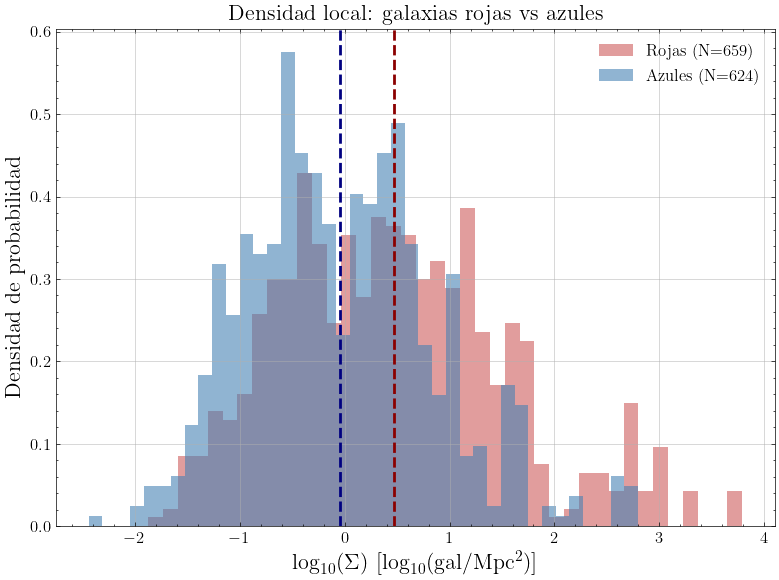

Promedio rojas = 2.932 gal/Mpc²
Media aritmética = 96.796 gal/Mpc²
Promedio azules = 0.907 gal/Mpc²
Media aritmética = 12.404 gal/Mpc²


In [18]:
sub_roja = sub[sub['poblacion'] == 'roja'].copy()
sub_azul = sub[sub['poblacion'] == 'azul'].copy()
print(f"Galaxias rojas: {len(sub_roja)}, azules: {len(sub_azul)}")

log_roja = np.log10(sub_roja['densidad_local'])
log_azul = np.log10(sub_azul['densidad_local'])


fig, ax = plt.subplots(figsize=(8, 6))
ax.hist(log_roja, bins=40, alpha=0.6, color='indianred', label=f'Rojas (N={len(sub_roja)})', density=True)
ax.hist(log_azul, bins=40, alpha=0.6, color='steelblue', label=f'Azules (N={len(sub_azul)})', density=True)

ax.axvline(log_roja.mean(), color='darkred', linestyle='--', lw=2)
ax.axvline(log_azul.mean(), color='navy', linestyle='--', lw=2)

ax.set_xlabel(r'$\log_{10}(\Sigma)$ [$\log_{10}$(gal/Mpc$^2$)]', fontsize=16)
ax.set_ylabel('Densidad de probabilidad', fontsize=16)
ax.legend(fontsize=12)
ax.set_title('Densidad local: galaxias rojas vs azules', fontsize=16)
ax.grid(True, alpha=0.7)
ax.tick_params(labelsize=12)

plt.tight_layout()
plt.savefig('images/7 - densidad_roja_azul.pdf', dpi=150)
plt.show()

print(f"Promedio rojas = {10**log_roja.mean():.3f} gal/Mpc²")
print(f"Media aritmética = {sub_roja['densidad_local'].mean():.3f} gal/Mpc²")

print(f"Promedio azules = {10**log_azul.mean():.3f} gal/Mpc²")
print(f"Media aritmética = {sub_azul['densidad_local'].mean():.3f} gal/Mpc²")

In [19]:
print(rf'H0: Ambas distribuciones provienen de la misma población')
stat_ks, p_ks = ks_2samp(log_roja, log_azul)
print(rf"KS test: estadístico={stat_ks:.4f}, p-valor={p_ks:.2e}")

if p_ks < 0.05:
    print(rf"Se rechaza H0: las distribuciones de densidad son significativamente distintas (p<0.05)")
else:
    print("No hay evidencia suficiente para decir que las distribuciones difieren")

H0: Ambas distribuciones provienen de la misma población
KS test: estadístico=0.2234, p-valor=1.63e-14
Se rechaza H0: las distribuciones de densidad son significativamente distintas (p<0.05)


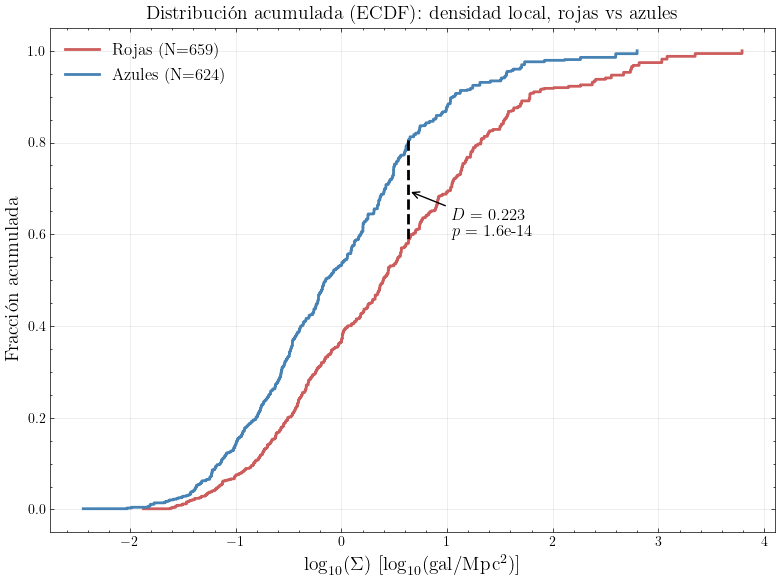

Razón de densidades (roja/azul) = 3.23x


In [20]:
x_roja, y_roja = ecdf(log_roja)
x_azul, y_azul = ecdf(log_azul)

fig, ax = plt.subplots(figsize=(8, 6))
ax.step(x_roja, y_roja, where='post', color='indianred', lw=2, label=f'Rojas (N={len(log_roja)})')
ax.step(x_azul, y_azul, where='post', color='steelblue', lw=2, label=f'Azules (N={len(log_azul)})')

x_common = np.sort(np.concatenate([x_roja, x_azul]))
y_roja_en_x = np.searchsorted(x_roja, x_common, side='right') / len(x_roja)
y_azul_en_x = np.searchsorted(x_azul, x_common, side='right') / len(x_azul)
diffs = np.abs(y_roja_en_x - y_azul_en_x)
idx_max = np.argmax(diffs)
x_ks = x_common[idx_max]

ax.vlines(x_ks, y_azul_en_x[idx_max], y_roja_en_x[idx_max], 
          color='black', lw=2, linestyle='--', zorder=5)
ax.annotate(f'$D$ = {stat_ks:.3f}\n$p$ = {p_ks:.1e}', 
            xy=(x_ks, (y_roja_en_x[idx_max] + y_azul_en_x[idx_max]) / 2),
            xytext=(x_ks + 0.4, (y_roja_en_x[idx_max] + y_azul_en_x[idx_max]) / 2 - 0.1),
            fontsize=12, arrowprops=dict(arrowstyle='->', color='black'))

ax.set_xlabel(r'$\log_{10}(\Sigma)$ [$\log_{10}$(gal/Mpc$^2$)]', fontsize=14)
ax.set_ylabel('Fracción acumulada', fontsize=14)
ax.legend(fontsize=12, loc='upper left')
ax.set_title('Distribución acumulada (ECDF): densidad local, rojas vs azules', fontsize=14)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('images/7 - ecdf_densidad.pdf', dpi=150)
plt.show()

print(f"Razón de densidades (roja/azul) = {10**(log_roja.mean() - log_azul.mean()):.2f}x")

entorno
poco denso    840
denso         840
Name: count, dtype: int64


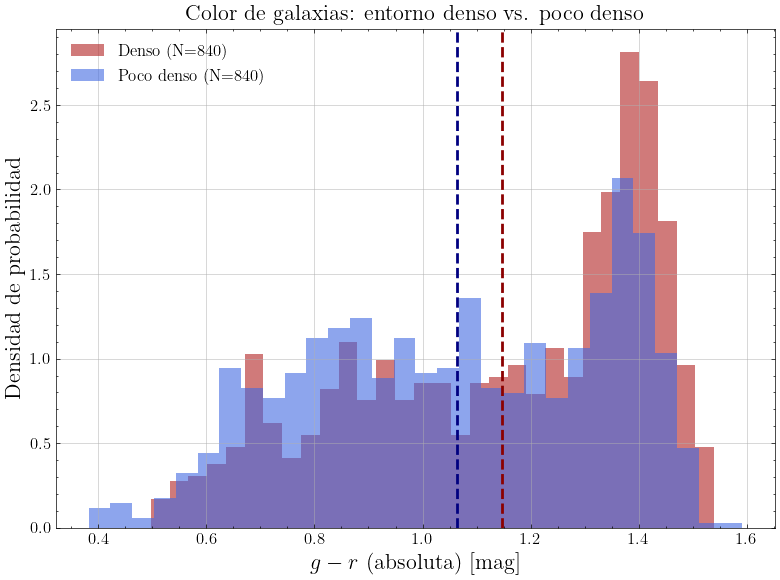

Color promedio (denso) = 1.147
Color promedio (poco denso) = 1.063
KS test: estadístico=0.1571, p-valor=1.82e-09
Se rechaza H0: el color difiere significativamente entre entornos (p<0.05)


In [21]:
mediana_densidad = sub['densidad_local'].median()
sub['entorno'] = np.where(sub['densidad_local'] >= mediana_densidad, 'denso', 'poco denso')
print(sub['entorno'].value_counts())

color_denso_valores     = sub.loc[sub['entorno']=='denso', 'color_gr']
color_pocodenso_valores = sub.loc[sub['entorno']=='poco denso', 'color_gr']

fig, ax = plt.subplots(figsize=(8, 6))
ax.hist(color_denso_valores, bins=30, alpha=0.6, color='firebrick', 
        label=f'Denso (N={len(color_denso_valores)})', density=True)
ax.hist(color_pocodenso_valores, bins=30, alpha=0.6, color='royalblue', 
        label=f'Poco denso (N={len(color_pocodenso_valores)})', density=True)
ax.axvline(color_denso_valores.mean(), color='darkred', linestyle='--', lw=2)
ax.axvline(color_pocodenso_valores.mean(), color='navy', linestyle='--', lw=2)

ax.set_xlabel('$g - r$ (absoluta) [mag]', fontsize=16)
ax.set_ylabel('Densidad de probabilidad', fontsize=16)
ax.legend(fontsize=12)
ax.set_title('Color de galaxias: entorno denso vs. poco denso', fontsize=16)
ax.tick_params(labelsize=12)
ax.grid(True, alpha=0.7)

plt.tight_layout()
plt.savefig('images/8 - color_vs_entorno.pdf', dpi=150)
plt.show()

print(f"Color promedio (denso) = {color_denso_valores.mean():.3f}")
print(f"Color promedio (poco denso) = {color_pocodenso_valores.mean():.3f}")

stat_ks8, p_ks8 = ks_2samp(color_denso_valores, color_pocodenso_valores)
print(f"KS test: estadístico={stat_ks8:.4f}, p-valor={p_ks8:.2e}")
if p_ks8 < 0.05:
    print("Se rechaza H0: el color difiere significativamente entre entornos (p<0.05)")
else:
    print("No hay evidencia suficiente para decir que el color difiere entre entornos")

poblacion   azul  green_valley  roja
entorno                             
denso        265           184   391
poco denso   359           213   268
entorno
denso         0.465476
poco denso    0.319048
dtype: float64


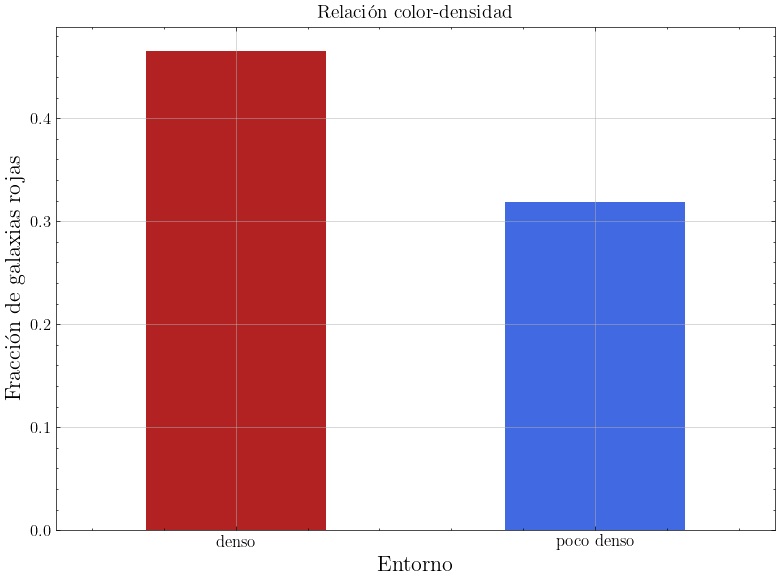

In [22]:
tabla = pd.crosstab(sub['entorno'], sub['poblacion'])
print(tabla)

frac_roja = tabla['roja'] / tabla.sum(axis=1)
print(frac_roja)

fig, ax = plt.subplots(figsize=(8, 6))
frac_roja.plot(kind='bar', ax=ax, color=['firebrick', 'royalblue'])
ax.set_ylabel('Fracción de galaxias rojas', fontsize=16)
ax.set_xlabel('Entorno', fontsize=16)
ax.set_title('Relación color-densidad', fontsize=14)
ax.tick_params(labelsize=12, rotation=0)
ax.grid(True, alpha=0.7)

plt.tight_layout()
plt.savefig('images/8 - fraccion_roja_entorno.pdf', dpi=150)
plt.show()